In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive

drive.mount('/content/drive')
df1 = pd.read_csv('/content/drive/MyDrive/Proyecto EOI/yelpzip.csv')



# Mostrar información técnica (tipos de datos, nulos)
print("\nInformación del DataFrame:")
df1.info()
df1.head()
print(df1.columns)


Mounted at /content/drive

Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 608458 entries, 0 to 608457
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Unnamed: 0  608458 non-null  int64  
 1   user_id     608458 non-null  int64  
 2   prod_id     608458 non-null  int64  
 3   rating      608458 non-null  float64
 4   label       608458 non-null  int64  
 5   date        608458 non-null  object 
 6   text        608458 non-null  object 
 7   tag         608458 non-null  object 
dtypes: float64(1), int64(4), object(3)
memory usage: 37.1+ MB
Index(['Unnamed: 0', 'user_id', 'prod_id', 'rating', 'label', 'date', 'text',
       'tag'],
      dtype='object')


In [3]:
print(df1['label'].value_counts())
print(df1['tag'].value_counts())

label
 1    528019
-1     80439
Name: count, dtype: int64
tag
real    528019
fake     80439
Name: count, dtype: int64


In [4]:
df1.drop(['label', 'date'], axis=1, inplace=True)

In [5]:
talla_mapping = {'real':0, 'fake':1}# 0=real 1=fake
df1['tag'] = df1['tag'].map(talla_mapping)
df1.head()

,Unnamed: 0,user_id,prod_id,rating,text,tag
0,0,5044,0,1.0,"Drinks were bad, the hot chocolate was watered...",1
1,1,5045,0,1.0,This was the worst experience I've ever had a ...,1
2,2,5046,0,3.0,This is located on the site of the old Spruce ...,1
3,3,5047,0,5.0,I enjoyed coffee and breakfast twice at Toast ...,1
4,4,5048,0,5.0,I love Toast! The food choices are fantastic -...,1


In [6]:
from sklearn.utils import resample
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix
# 1. Separar las clases (Asumiendo que 1=Fake, 0=Real, verifica tus etiquetas)
# Si tus etiquetas son al revés, cambia los números aquí
df_fake = df1[df1['tag'] == 1] # Minoría
df_real = df1[df1['tag'] == 0] # Mayoría

# 2. Hacemos Downsample de la mayoría (Reales)
df_real_downsampled = resample(df_real,
                               replace=False,    # No repetir muestras
                               n_samples=len(df_fake), # Igualar al número de Fakes (42k)
                               random_state=42)

# 3. Combinar de nuevo
df_balanceado = pd.concat([df_real_downsampled, df_fake])

# 4. Verificar
print(df_balanceado['tag'].value_counts())




tag
0    80439
1    80439
Name: count, dtype: int64


MULTINOMIAL NB


--- Reporte de Clasificación ---
               precision    recall  f1-score   support

   Humano (0)       0.67      0.65      0.66     16088
Ordenador (1)       0.66      0.68      0.67     16088

     accuracy                           0.67     32176
    macro avg       0.67      0.67      0.67     32176
 weighted avg       0.67      0.67      0.67     32176

Precisión del modelo: 0.67


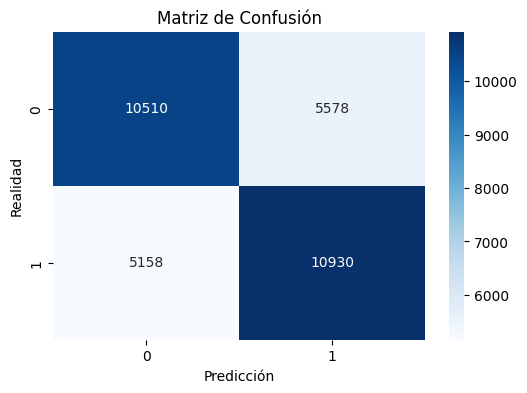

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

X = df_balanceado['text']
y = df_balanceado['tag']

vectorizer = TfidfVectorizer(stop_words='english', max_features=15000, ngram_range=(1, 2))
X_vectorizado = vectorizer.fit_transform(X)


X_train, X_test, y_train, y_test = train_test_split(X_vectorizado, y, test_size=0.2, random_state=42, stratify=y)
modelo = MultinomialNB(alpha=0.5)#mejor este alpha que alpha=1.0
modelo.fit(X_train, y_train)

# 5. EVALUACIÓN
y_pred = modelo.predict(X_test)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred, target_names=['Humano (0)', 'Ordenador (1)']))

print(f"Precisión del modelo: {accuracy_score(y_test, y_pred):.2f}")
# Mostrar matriz de confusión visual
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

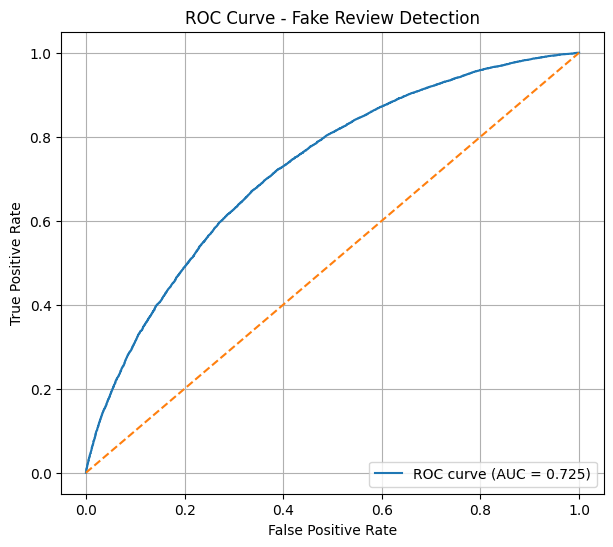

In [ ]:
from sklearn.metrics import roc_curve, auc
# Probabilidades para la clase fake (label = 1)
y_proba =modelo.predict_proba(X_test)[:, 1]

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Área bajo la curva
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fake Review Detection')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

REGRESIÓN LOGISTICA

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

X = df_balanceado['text']
y = df_balanceado['tag']


vectorizer=TfidfVectorizer(stop_words='english', max_df=0.7,ngram_range=(1, 2))
X_vectorizado = vectorizer.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_vectorizado, y, test_size=0.2, random_state=42,stratify=y) #mejora con stratify=y


# Definir modelo
logreg = LogisticRegression(max_iter=1000,class_weight='balanced')

# Hiperparámetros para ajustar
param_grid = {
    'C': [0.01, 0.1, 1, 10],       # regularización inversa
    'penalty': ['l2'],             # L2 regularization
    'solver': ['lbfgs']            # solver compatible
}

# GridSearchCV con validación cruzada
grid = GridSearchCV(logreg, param_grid, cv=5, scoring='roc_auc')
grid.fit(X_train, y_train)

# Mejor modelo
best_logreg = grid.best_estimator_
print(f"Mejor modelo: {best_logreg}")
print(f"Mejores hiperparámetros: {grid.best_params_}")


Mejor modelo: LogisticRegression(C=1, class_weight='balanced', max_iter=1000)
Mejores hiperparámetros: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

X = df_balanceado['text']
y = df_balanceado['tag']


vectorizer=TfidfVectorizer(stop_words='english', max_df=0.7,ngram_range=(1, 2))
X_vectorizado = vectorizer.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_vectorizado, y, test_size=0.2, random_state=42,stratify=y) #mejora con stratify=y


# Definir modelo
logreg = LogisticRegression(max_iter=1000,class_weight='balanced', C=1)

logreg.fit(X_train, y_train)



LogisticRegression(C=1, class_weight='balanced', max_iter=1000)

              precision    recall  f1-score   support

           0       0.68      0.67      0.68     16088
           1       0.68      0.69      0.68     16088

    accuracy                           0.68     32176
   macro avg       0.68      0.68      0.68     32176
weighted avg       0.68      0.68      0.68     32176

ROC-AUC: 0.742261596756749


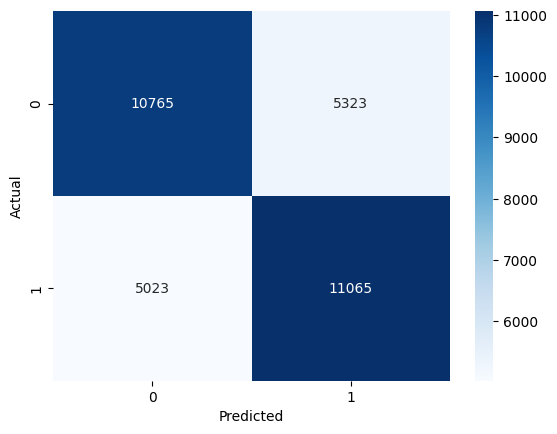

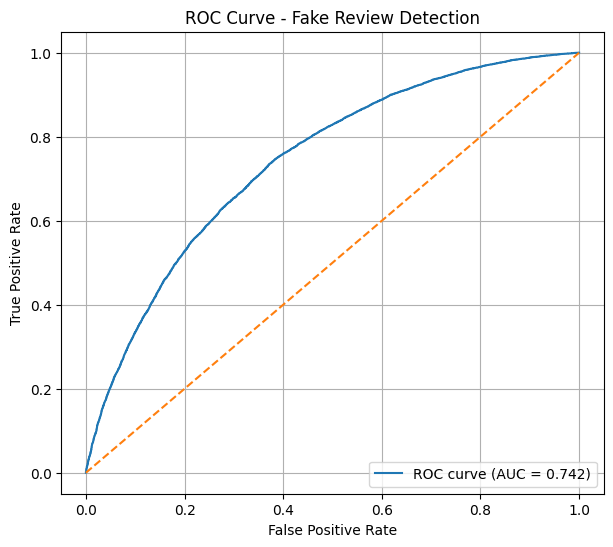

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
y_pred = logreg.predict(X_test)
y_prob = logreg.predict_proba(X_test)[:,1]

# Métricas
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
# Matriz de confusión
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Área bajo la curva
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fake Review Detection')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

LINEAR SVC

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer


X = df_balanceado['text']
y = df_balanceado['tag']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipeline = Pipeline([
    # Usamos nuestra clase personalizada en lugar de TfidfVectorizer
    ('tfidf', TfidfVectorizer(stop_words='english', max_df=0.7,ngram_range=(1, 3))),#mejora con ngram_range=(1, 3)
    ('clf', LinearSVC(class_weight='balanced', random_state=42, max_iter=5000, C=10))
])


# 4. Entrenar
pipeline.fit(X_train, y_train)



Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.7, ngram_range=(1, 3),
                                 stop_words='english')),
                ('clf',
                 LinearSVC(C=10, class_weight='balanced', max_iter=5000,
                           random_state=42))])

              precision    recall  f1-score   support

           0       0.64      0.73      0.68     16088
           1       0.68      0.60      0.64     16088

    accuracy                           0.66     32176
   macro avg       0.66      0.66      0.66     32176
weighted avg       0.66      0.66      0.66     32176


--- Matriz de Confusión ---
[[11672  4416]
 [ 6506  9582]]


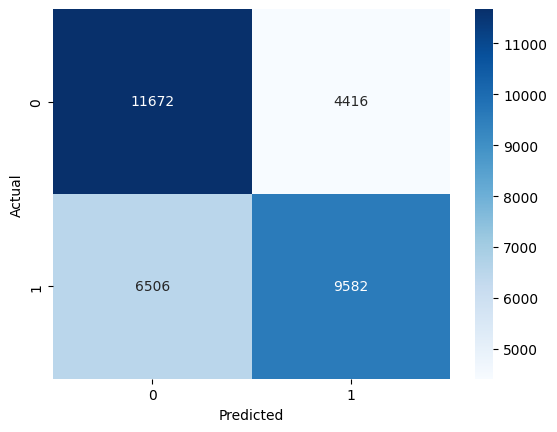

In [ ]:
predictions = pipeline.predict(X_test)

print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()




In [ ]:
%pip install gensim



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 70.6 MB/s eta 0:00:00


In [ ]:
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from gensim.utils import simple_preprocess
import numpy as np
class Word2VecTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=300, window=10, min_count=5, workers=4, epochs=20):
        self.vector_size = vector_size
        self.window = window     # Ventana amplia para capturar historias de Yelp
        self.min_count = min_count
        self.workers = workers
        self.epochs = epochs
        self.model = None

    def fit(self, X, y=None):
        print("Tokenizando datos...")
        sentences = [simple_preprocess(text) for text in X]

        print(f"Entrenando Word2Vec (Window={self.window})...")
        self.model = Word2Vec(sentences,
                              vector_size=self.vector_size,
                              window=self.window,
                              min_count=self.min_count,
                              workers=self.workers,
                              epochs=self.epochs)
        return self

    def transform(self, X):
        X_transformed = []
        for text in X:
            words = simple_preprocess(text)
            # Filtramos palabras conocidas
            vectors = [self.model.wv[word] for word in words if word in self.model.wv]

            if vectors:
                # Promedio simple (Mean Embedding)
                X_transformed.append(np.mean(vectors, axis=0))
            else:
                X_transformed.append(np.zeros(self.vector_size))

        return np.array(X_transformed)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC, SVC
from sklearn.preprocessing import StandardScaler # OBLIGATORIO para SVM
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
X = df_balanceado['text']
y = df_balanceado['tag']

# División estratificada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Pipeline: W2V + Scaler + SVM
# Usamos LinearSVC por eficiencia. Si usaras SVC() normal tardaría horas.
pipeline = Pipeline([
    ('w2v', Word2VecTransformer(vector_size=300, window=10, min_count=5)),
    ('scaler', StandardScaler()), # SVM es muy sensible a la escala, esto es vital
    ('clf', LinearSVC(class_weight='balanced',
                      dual=False,      # dual=False es mejor cuando n_samples > n_features
                      max_iter=5000,
                      random_state=42))
])

# 4. Entrenar
print("Entrenando SVM (LinearSVC)...")
pipeline.fit(X_train, y_train)

Entrenando SVM (LinearSVC)...
Tokenizando datos...
Entrenando Word2Vec (Window=10)...


Pipeline(steps=[('w2v', Word2VecTransformer()), ('scaler', StandardScaler()),
                ('clf',
                 LinearSVC(class_weight='balanced', dual=False, max_iter=5000,
                           random_state=42))])

              precision    recall  f1-score   support

           0       0.65      0.70      0.68     16088
           1       0.68      0.63      0.65     16088

    accuracy                           0.66     32176
   macro avg       0.66      0.66      0.66     32176
weighted avg       0.66      0.66      0.66     32176


--- Matriz de Confusión ---
[[11271  4817]
 [ 6016 10072]]


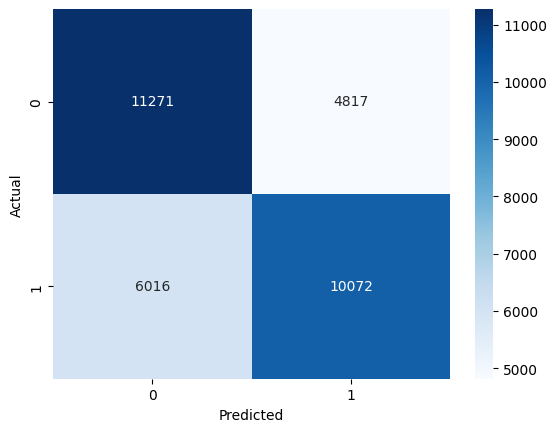

In [ ]:
predictions = pipeline.predict(X_test)

print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


XGBoost

In [ ]:
X = df_balanceado['text']
y = df_balanceado['tag']

# División estratificada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

from xgboost import XGBClassifier

pipeline = Pipeline([
    ('w2v', Word2VecTransformer(vector_size=300, window=10, min_count=5)),
    ('clf', XGBClassifier(n_estimators=500,
                          learning_rate=0.1,
                          max_depth=6,
                          n_jobs=-1, # Usa todos los núcleos
                          random_state=42))
])

# 4. Entren
pipeline.fit(X_train, y_train)

Entrenando SVM (LinearSVC)...
Tokenizando datos...
Entrenando Word2Vec (Window=10)...


Pipeline(steps=[('w2v', Word2VecTransformer()),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric=None,
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=500, n_jobs=-1,
                               num_parallel_tree=None, ...))])

              precision    recall  f1-score   support

           0       0.67      0.66      0.67     16088
           1       0.67      0.68      0.67     16088

    accuracy                           0.67     32176
   macro avg       0.67      0.67      0.67     32176
weighted avg       0.67      0.67      0.67     32176


--- Matriz de Confusión ---
[[10620  5468]
 [ 5143 10945]]


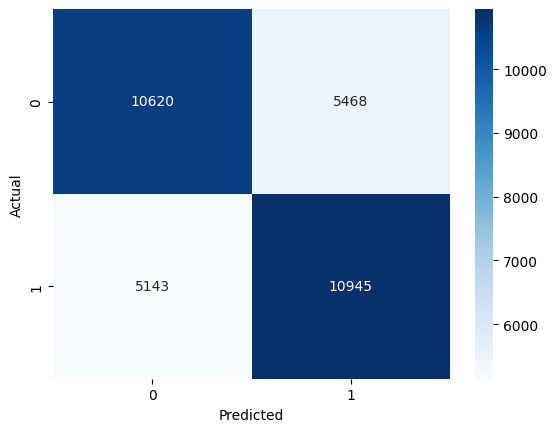

In [ ]:
predictions = pipeline.predict(X_test)

print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [ ]:
from xgboost import XGBClassifier
X = df_balanceado['text']
y = df_balanceado['tag']

# División estratificada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipeline_xgb = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))), # Menos features para XGBoost
    ('clf', XGBClassifier(n_estimators=100,
                          n_jobs=-1,
                          eval_metric='logloss',
                          use_label_encoder=False))
])

pipeline_xgb.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [11:14:18] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

              precision    recall  f1-score   support

           0       0.68      0.62      0.65     16088
           1       0.65      0.71      0.68     16088

    accuracy                           0.67     32176
   macro avg       0.67      0.67      0.66     32176
weighted avg       0.67      0.67      0.66     32176


--- Matriz de Confusión ---
[[ 9970  6118]
 [ 4643 11445]]


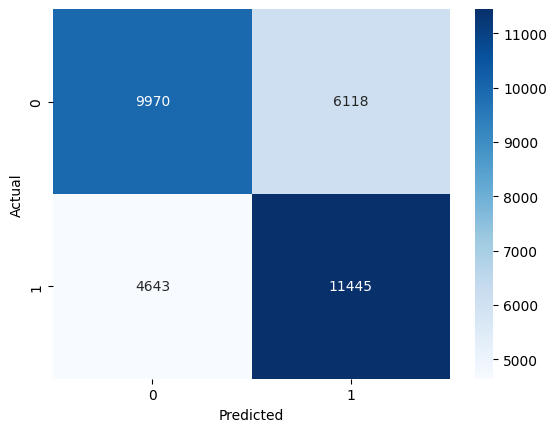

In [ ]:
predictions = pipeline_xgb.predict(X_test)

print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

RANDOM FOREST

INGIENERÍA DE CARACTERÍSTICAS

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.utils import resample
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

# 1. CARGA LIMPIA (Asegúrate de tener prod_id y rating)
df1 = pd.read_csv('yelpzip.csv', engine='python', on_bad_lines='skip')

# Eliminar columnas basura si existen
cols_to_drop = [c for c in df1.columns if 'Unnamed' in c or c == 'date']
df1.drop(columns=cols_to_drop, inplace=True)

# 2. INGENIERÍA DE CARACTERÍSTICAS (¡La clave!)

# A) Calcular el promedio de estrellas de cada PRODUCTO
# Esto nos dice la "verdad" sobre la calidad del producto según la masa
prod_avg = df1.groupby('prod_id')['rating'].mean().reset_index()
prod_avg.columns = ['prod_id', 'avg_prod_rating']

# Unimos este promedio al dataframe principal
df1 = pd.merge(df1, prod_avg, on='prod_id', how='left')

# B) Calcular la DESVIACIÓN (Cuán lejos está mi nota del promedio)
# Si el producto tiene un 4 y yo le doy un 1, la desviación es 3.
df1['rating_deviation'] = abs(df1['rating'] - df1['avg_prod_rating'])

# C) Calcular Actividad del Usuario (Opcional pero potente)
# ¿Cuántas reviews ha escrito este usuario en total?
user_counts = df1.groupby('user_id').size().reset_index(name='user_review_count')
df1 = pd.merge(df1, user_counts, on='user_id', how='left')

# 3. BALANCEO DE DATOS (Undersampling)
# Ahora que tenemos las features calculadas, balanceamos
df_fake = df1[df1['label'] == -1] # Asumo -1 es fake en YelpZip original
df_real = df1[df1['label'] == 1]  # Asumo 1 es real

# Downsample
df_real_down = resample(df_real, replace=False, n_samples=len(df_fake), random_state=42)
df_bal = pd.concat([df_real_down, df_fake])

# 4. PREPARACIÓN FINAL
# Texto
tfidf = TfidfVectorizer(max_features=15000, stop_words='english', ngram_range=(1,2))
X_text = tfidf.fit_transform(df_bal['text']) # O 'reviewContent'

# Numéricos (Rating, Desviación, Conteo de reviews)
# Normalizamos para que el modelo no se confunda con escalas
scaler = StandardScaler()
X_num = scaler.fit_transform(df_bal[['rating', 'rating_deviation', 'user_review_count']])

# Unir todo
X = hstack([X_text, X_num])
y = df_bal['label'] # Asegúrate que sean números (0 y 1 preferiblemente)

# 5. ENTRENAMIENTO
X_train, X_test_rf, y_train, y_test_rf = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Entrenando Random Forest con Metadatos de Comportamiento...")
model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
model.fit(X_train, y_train)

# 6. RESULTADOS
y_pred = model.predict(X_test_rf)
print(f"Precisión: {accuracy_score(y_test_rf, y_pred):.3f}")
print(classification_report(y_test_rf, y_pred))

# Ver importancia
feats = ['rating', 'deviation', 'user_activity']
imps = model.feature_importances_[-3:]
print("\nImportancia de las nuevas variables:")
for f, i in zip(feats, imps):
    print(f"{f}: {i:.4f}")

Entrenando Random Forest con Metadatos de Comportamiento...
Precisión: 0.677
              precision    recall  f1-score   support

          -1       0.67      0.69      0.68       511
           1       0.68      0.66      0.67       510

    accuracy                           0.68      1021
   macro avg       0.68      0.68      0.68      1021
weighted avg       0.68      0.68      0.68      1021


Importancia de las nuevas variables:
rating: 0.0105
deviation: 0.0154
user_activity: 0.0132


LSTM

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Concatenate, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils import resample



df1 = pd.read_csv('yelpzip.csv', engine='python', on_bad_lines='skip')

df1.drop(['Unnamed: 0'], axis=1, inplace=True)

# 2. INGENIERÍA DE CARACTERÍSTICAS (¡La clave!)

# A) Calcular el promedio de estrellas de cada PRODUCTO
# Esto nos dice la "verdad" sobre la calidad del producto según la masa
prod_avg = df1.groupby('prod_id')['rating'].mean().reset_index()
prod_avg.columns = ['prod_id', 'avg_prod_rating']

# Unimos este promedio al dataframe principal
df1 = pd.merge(df1, prod_avg, on='prod_id', how='left')

# B) Calcular la DESVIACIÓN (Cuán lejos está mi nota del promedio)
# Si el producto tiene un 4 y yo le doy un 1, la desviación es 3.
df1['rating_deviation'] = abs(df1['rating'] - df1['avg_prod_rating'])

# C) Calcular Actividad del Usuario (Opcional pero potente)
# ¿Cuántas reviews ha escrito este usuario en total?
user_counts = df1.groupby('user_id').size().reset_index(name='user_review_count')
df1 = pd.merge(df1, user_counts, on='user_id', how='left')

# 3. BALANCEO DE DATOS (Undersampling)
# Ahora que tenemos las features calculadas, balanceamos
df_fake = df1[df1['tag'] == 'fake'] # Asumo -1 es fake en YelpZip original
df_real = df1[df1['tag'] == 'real']  # Asumo 1 es real

# Downsample
df_real_down = resample(df_real, replace=False, n_samples=len(df_fake), random_state=42)
df_bal = pd.concat([df_real_down, df_fake])


# Normalizamos los datos numéricos (CRÍTICO para redes neuronales)
scaler = StandardScaler()

X_num = scaler.fit_transform(df_bal[['rating', 'rating_deviation', 'user_review_count']])

df_bal['tag'] = df_bal['tag'].map({'fake': 1, 'real': 0})

# 2. Vuelve a asignar y
y = df_bal['tag'].values


# --- 2. PROCESAMIENTO DE TEXTO PARA LSTM ---
# Parámetros clave
MAX_WORDS = 20000      # Tamaño del vocabulario (palabras más comunes)
MAX_LEN = 150          # Longitud máxima de la reseña (cortamos o rellenamos)
EMBEDDING_DIM = 64    # Dimensión del vector denso para cada palabra

print("Tokenizando textos...")
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df_bal['text'].astype(str))
sequences = tokenizer.texts_to_sequences(df_bal['text'].astype(str))

print("Padding de secuencias...")
X_text = pad_sequences(sequences, maxlen=MAX_LEN, padding='pre', truncating='post')

# Split de entrenamiento (¡Importante!: separar texto y números coordinadamente)
X_temp_train, X_text_test, X_tempnum_train, X_num_test, y_temp, y_test = train_test_split(
    X_text, X_num, y, test_size=0.2, random_state=42, stratify=y
)

#dividir temp en train y val
X_text_train, X_text_val, X_num_train, X_num_val, y_train, y_val= train_test_split(
    X_temp_train, X_tempnum_train, y_temp, test_size=0.2, random_state=42, stratify=y_temp
)


# A) Rama de Texto (LSTM)
input_text = Input(shape=(MAX_LEN,), name='input_text')
x1 = Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM)(input_text)
x1 = LSTM(64, return_sequences=False)(x1)


# B) Rama Numérica (Metadatos)
input_num = Input(shape=(X_num.shape[1],), name='input_num')
x2 = Dense(32, activation='relu')(input_num)
x2 = BatchNormalization()(x2) # Ayuda a estabilizar los números

# C) Concatenación
concatenated = Concatenate()([x1, x2])

# D) Capas Densas Finales (Clasificación)
x = Dense(64, activation='relu')(concatenated)
x = Dropout(0.5)(x)
output = Dense(1, activation='sigmoid', name='output')(x)

model = Model(inputs=[input_text, input_num], outputs=output)

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

# --- 4. ENTRENAMIENTO ---
print("\nIniciando entrenamiento híbrido...")
history = model.fit(
    {'input_text': X_text_train, 'input_num': X_num_train},
    y_train,
    epochs=10,                # Pocas épocas suelen bastar
    batch_size=128,           # Batch grande para velocidad
    validation_data=({'input_text': X_text_val, 'input_num': X_num_val}, y_val),
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)]
)

# --- 5. EVALUACIÓN ---
print("\nEvaluando modelo...")
y_pred_prob = model.predict({'input_text': X_text_test, 'input_num': X_num_test})
y_pred = (y_pred_prob > 0.5).astype(int)

print(f"Accuracy Final: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

Tokenizando textos...
Padding de secuencias...


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_text          │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_num           │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 150, 64)   │  1,280,000 │ input_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        128 │ input_num[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64)        │     33,024 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 96)        │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      6,208 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,319,553 (5.03 MB)

 Trainable params: 1,319,489 (5.03 MB)

 Non-trainable params: 64 (256.00 B)


Iniciando entrenamiento híbrido...
Epoch 1/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6308 - loss: 0.6410 - val_accuracy: 0.6792 - val_loss: 0.5967
Epoch 2/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7145 - loss: 0.5623 - val_accuracy: 0.6986 - val_loss: 0.5644
Epoch 3/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7568 - loss: 0.5021 - val_accuracy: 0.6902 - val_loss: 0.5933
Epoch 4/10
183/183 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8138 - loss: 0.4137 - val_accuracy: 0.6782 - val_loss: 0.6433

Evaluando modelo...
228/228 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Accuracy Final: 0.7043
              precision    recall  f1-score   support

           0       0.72      0.68      0.70      3644
           1       0.69      0.73      0.71      3643

    accuracy                           0.70      7287
   macro avg       0.70      0.70      0.70      7287
weighted avg       0.70      0.70      0.70      7287



In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Concatenate, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils import resample
from tensorflow.keras.layers import Bidirectional


df1 = pd.read_csv('yelpzip.csv', engine='python', on_bad_lines='skip')

df1.drop(['Unnamed: 0'], axis=1, inplace=True)

# 2. INGENIERÍA DE CARACTERÍSTICAS (¡La clave!)

# A) Calcular el promedio de estrellas de cada PRODUCTO
# Esto nos dice la "verdad" sobre la calidad del producto según la masa
prod_avg = df1.groupby('prod_id')['rating'].mean().reset_index()
prod_avg.columns = ['prod_id', 'avg_prod_rating']

# Unimos este promedio al dataframe principal
df1 = pd.merge(df1, prod_avg, on='prod_id', how='left')

# B) Calcular la DESVIACIÓN (Cuán lejos está mi nota del promedio)
# Si el producto tiene un 4 y yo le doy un 1, la desviación es 3.
df1['rating_deviation'] = abs(df1['rating'] - df1['avg_prod_rating'])

# C) Calcular Actividad del Usuario (Opcional pero potente)
# ¿Cuántas reviews ha escrito este usuario en total?
user_counts = df1.groupby('user_id').size().reset_index(name='user_review_count')
df1 = pd.merge(df1, user_counts, on='user_id', how='left')

# 3. BALANCEO DE DATOS (Undersampling)
# Ahora que tenemos las features calculadas, balanceamos
df_fake = df1[df1['tag'] == 'fake'] # Asumo -1 es fake en YelpZip original
df_real = df1[df1['tag'] == 'real']  # Asumo 1 es real

# Downsample
df_real_down = resample(df_real, replace=False, n_samples=len(df_fake), random_state=42)
df_bal = pd.concat([df_real_down, df_fake])


# Normalizamos los datos numéricos (CRÍTICO para redes neuronales)
scaler = StandardScaler()

X_num = scaler.fit_transform(df_bal[['rating', 'rating_deviation', 'user_review_count']])

df_bal['tag'] = df_bal['tag'].map({'fake': 1, 'real': 0})

# 2. Vuelve a asignar y
y = df_bal['tag'].values


# --- 2. PROCESAMIENTO DE TEXTO PARA LSTM ---
# Parámetros clave
MAX_WORDS = 20000      # Tamaño del vocabulario (palabras más comunes)
MAX_LEN = 150          # Longitud máxima de la reseña (cortamos o rellenamos)
EMBEDDING_DIM = 64    # Dimensión del vector denso para cada palabra

print("Tokenizando textos...")
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df_bal['text'].astype(str))
sequences = tokenizer.texts_to_sequences(df_bal['text'].astype(str))

print("Padding de secuencias...")
X_text = pad_sequences(sequences, maxlen=MAX_LEN, padding='pre', truncating='post')

# Split de entrenamiento (¡Importante!: separar texto y números coordinadamente)
X_temp_train, X_text_test, X_tempnum_train, X_num_test, y_temp, y_test = train_test_split(
    X_text, X_num, y, test_size=0.2, random_state=42, stratify=y
)

#dividir temp en train y val
X_text_train, X_text_val, X_num_train, X_num_val, y_train, y_val= train_test_split(
    X_temp_train, X_tempnum_train, y_temp, test_size=0.2, random_state=42, stratify=y_temp
)


# A) Rama de Texto (LSTM)
input_text = Input(shape=(MAX_LEN,), name='input_text')
x1 = Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM)(input_text)
x1 = Bidirectional(LSTM(64, return_sequences=False))(x1)


# B) Rama Numérica (Metadatos)
input_num = Input(shape=(X_num.shape[1],), name='input_num')
x2 = Dense(32, activation='relu')(input_num)
x2 = BatchNormalization()(x2) # Ayuda a estabilizar los números

# C) Concatenación
concatenated = Concatenate()([x1, x2])

# D) Capas Densas Finales (Clasificación)
x = Dense(64, activation='relu')(concatenated)
x = Dropout(0.5)(x)
output = Dense(1, activation='sigmoid', name='output')(x)

modelLSTM = Model(inputs=[input_text, input_num], outputs=output)

modelLSTM.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

modelLSTM.summary()

# --- 4. ENTRENAMIENTO ---
print("\nIniciando entrenamiento híbrido...")
history = modelLSTM.fit(
    {'input_text': X_text_train, 'input_num': X_num_train},
    y_train,
    epochs=10,                # Pocas épocas suelen bastar
    batch_size=128,           # Batch grande para velocidad
    validation_data=({'input_text': X_text_val, 'input_num': X_num_val}, y_val),
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)]
)

# --- 5. EVALUACIÓN ---
print("\nEvaluando modelo...")
y_pred_prob = modelLSTM.predict({'input_text': X_text_test, 'input_num': X_num_test})
y_pred = (y_pred_prob > 0.5).astype(int)

print(f"Accuracy Final: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))


Tokenizando textos...
Padding de secuencias...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_text          │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_num           │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 64)   │  1,280,000 │ input_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        128 │ input_num[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ embedding[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32)        │        128 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 160)       │          0 │ bidirectional[0]… │
│ (Concatenate)       │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     10,304 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         65 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,356,673 (5.18 MB)

 Trainable params: 1,356,609 (5.18 MB)

 Non-trainable params: 64 (256.00 B)


Iniciando entrenamiento híbrido...
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.6164 - loss: 0.6436 - val_accuracy: 0.6617 - val_loss: 0.6156
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7179 - loss: 0.5569 - val_accuracy: 0.6739 - val_loss: 0.5925
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7650 - loss: 0.4961 - val_accuracy: 0.6674 - val_loss: 0.5946
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.8120 - loss: 0.4304 - val_accuracy: 0.6767 - val_loss: 0.6143

Evaluando modelo...
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Accuracy Final: 0.6661
              precision    recall  f1-score   support

           0       0.66      0.69      0.67      2496
           1       0.68      0.64      0.66      2496

    accuracy                           0.67      4992
   macro avg       0.67      0.67      0.67      4992
weighted avg       0.67      0.67      0.67      4992



[[11164  4924]
 [ 3350 12738]]

--- Matriz de Confusión ---


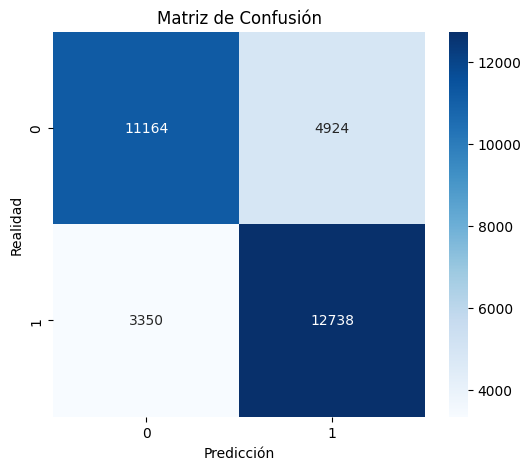

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
print(confusion_matrix(y_test, y_pred))
print("\n--- Matriz de Confusión ---")
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.ylabel('Realidad')
plt.xlabel('Predicción')
plt.show()

COMBINACIÓN

In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Concatenate, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils import resample
from tensorflow.keras.layers import Bidirectional
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler



df1 = pd.read_csv('yelpzip.csv', engine='python', on_bad_lines='skip')
df1.drop(['Unnamed: 0'], axis=1, inplace=True)


prod_avg = df1.groupby('prod_id')['rating'].mean().reset_index()
prod_avg.columns = ['prod_id', 'avg_prod_rating']

# Unimos este promedio al dataframe principal
df1 = pd.merge(df1, prod_avg, on='prod_id', how='left')

# B) Calcular la DESVIACIÓN (Cuán lejos está mi nota del promedio)
# Si el producto tiene un 4 y yo le doy un 1, la desviación es 3.
df1['rating_deviation'] = abs(df1['rating'] - df1['avg_prod_rating'])

# C) Calcular Actividad del Usuario (Opcional pero potente)
# ¿Cuántas reviews ha escrito este usuario en total?
user_counts = df1.groupby('user_id').size().reset_index(name='user_review_count')
df1 = pd.merge(df1, user_counts, on='user_id', how='left')


df_fake = df1[df1['tag'] == 'fake']
df_real = df1[df1['tag'] == 'real']

df_real_down = resample(df_real, replace=False, n_samples=len(df_fake), random_state=42)
df_bal = pd.concat([df_real_down, df_fake])


# Normalizamos los datos numéricos (CRÍTICO para redes neuronales)
scaler = StandardScaler()

X_num = scaler.fit_transform(df_bal[['rating', 'rating_deviation', 'user_review_count']])

df_bal['tag'] = df_bal['tag'].map({'fake': 1, 'real': 0})

y = df_bal['tag'].values




# 4. PREPARACIÓN FINAL
# Texto
tfidf = TfidfVectorizer(max_features=15000, stop_words='english', ngram_range=(1,2))
X_text = tfidf.fit_transform(df_bal['text']) # O 'reviewContent'


# Unir todo
X = hstack([X_text, X_num])

# 5. ENTRENAMIENTO
X_train, X_test_rf, y_train, y_test_rf = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Entrenando Random Forest con Metadatos de Comportamiento...")
model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
model.fit(X_train, y_train)

# 6. RESULTADOS
y_pred = model.predict(X_test_rf)
print(f"Precisión: {accuracy_score(y_test_rf, y_pred):.3f}")
print(classification_report(y_test_rf, y_pred))

# Ver importancia
feats = ['rating', 'deviation', 'user_activity']
imps = model.feature_importances_[-3:]
print("\nImportancia de las nuevas variables:")
for f, i in zip(feats, imps):
    print(f"{f}: {i:.4f}")


# --- 2. PROCESAMIENTO DE TEXTO PARA LSTM ---
# Parámetros clave
MAX_WORDS = 20000      # Tamaño del vocabulario (palabras más comunes)
MAX_LEN = 150          # Longitud máxima de la reseña (cortamos o rellenamos)
EMBEDDING_DIM = 64    # Dimensión del vector denso para cada palabra

print("Tokenizando textos...")
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df_bal['text'].astype(str))
sequences = tokenizer.texts_to_sequences(df_bal['text'].astype(str))

print("Padding de secuencias...")
X_text = pad_sequences(sequences, maxlen=MAX_LEN, padding='pre', truncating='post')

# Split de entrenamiento (¡Importante!: separar texto y números coordinadamente)
X_temp_train, X_text_test, X_tempnum_train, X_num_test, y_temp, y_test = train_test_split(
    X_text, X_num, y, test_size=0.2, random_state=42, stratify=y
)

#dividir temp en train y val
X_text_train, X_text_val, X_num_train, X_num_val, y_train, y_val= train_test_split(
    X_temp_train, X_tempnum_train, y_temp, test_size=0.2, random_state=42, stratify=y_temp
)


# A) Rama de Texto (LSTM)
input_text = Input(shape=(MAX_LEN,), name='input_text')
x1 = Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM)(input_text)
x1 = Bidirectional(LSTM(64, return_sequences=False))(x1)


# B) Rama Numérica (Metadatos)
input_num = Input(shape=(X_num.shape[1],), name='input_num')
x2 = Dense(32, activation='relu')(input_num)
x2 = BatchNormalization()(x2) # Ayuda a estabilizar los números

# C) Concatenación
concatenated = Concatenate()([x1, x2])

# D) Capas Densas Finales (Clasificación)
x = Dense(64, activation='relu')(concatenated)
x = Dropout(0.5)(x)
output = Dense(1, activation='sigmoid', name='output')(x)

modelLSTM = Model(inputs=[input_text, input_num], outputs=output)

modelLSTM.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

modelLSTM.summary()

# --- 4. ENTRENAMIENTO ---
print("\nIniciando entrenamiento híbrido...")
history = modelLSTM.fit(
    {'input_text': X_text_train, 'input_num': X_num_train},
    y_train,
    epochs=10,                # Pocas épocas suelen bastar
    batch_size=128,           # Batch grande para velocidad
    validation_data=({'input_text': X_text_val, 'input_num': X_num_val}, y_val),
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)]
)

# --- 5. EVALUACIÓN ---
print("\nEvaluando modelo...")
y_pred_prob = modelLSTM.predict({'input_text': X_text_test, 'input_num': X_num_test})
y_pred = (y_pred_prob > 0.5).astype(int)

print(f"Accuracy Final: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))



# ==============================================================================
# 7. CÁLCULO DEL ENSEMBLE (RF + LSTM)
# ==============================================================================
from sklearn.metrics import roc_auc_score

print("\n" + "="*40)
print("   CALCULANDO ENSEMBLE FINAL")
print("="*40)

# 1. Obtener probabilidades del Random Forest
# predict_proba devuelve [prob_clase0, prob_clase1]. Queremos la columna 1 (Fake)
# Usamos X_test_rf que definiste en la sección 5
probs_rf = model.predict_proba(X_test_rf)[:, 1]

# 2. Obtener probabilidades del LSTM
# predict devuelve un array de (N, 1). Usamos flatten() para hacerlo un vector plano
# Usamos el diccionario de inputs que definiste en la sección 5
probs_lstm = modelLSTM.predict({'input_text': X_text_test, 'input_num': X_num_test}).flatten()

# 3. Promedio de probabilidades
# Aquí puedes dar pesos si confías más en uno (ej: 0.4*RF + 0.6*LSTM)
probs_ensemble = (probs_rf + probs_lstm) / 2.0

# 4. Convertir a Clase Final (0 o 1) con umbral 0.5
y_pred_ensemble = (probs_ensemble > 0.5).astype(int)

# ==============================================================================
# 8. COMPARATIVA Y RESULTADOS
# ==============================================================================
print(f"\nAccuracy Ensemble: {accuracy_score(y_test, y_pred_ensemble):.4f}")
print(f"ROC AUC Score:     {roc_auc_score(y_test, probs_ensemble):.4f}")
print("-" * 50)
print("Reporte de Clasificación del Ensemble:")
print(classification_report(y_test, y_pred_ensemble))

# Comparación rápida
acc_rf = accuracy_score(y_test, model.predict(X_test_rf))
acc_lstm = accuracy_score(y_test, (probs_lstm > 0.5).astype(int))
acc_ens = accuracy_score(y_test, y_pred_ensemble)

print("\n--- RESUMEN DE MEJORA ---")
print(f"Random Forest solo: {acc_rf:.4f}")
print(f"LSTM solo:          {acc_lstm:.4f}")
print(f"Ensemble (Unión):   {acc_ens:.4f}")

if acc_ens > max(acc_rf, acc_lstm):
    print("✅ ¡El Ensemble ha mejorado el resultado!")
else:
    print("⚠️ El Ensemble no superó al mejor modelo individual (a veces pasa si son muy similares).")

Entrenando Random Forest con Metadatos de Comportamiento...
Precisión: 0.733
              precision    recall  f1-score   support

           0       0.74      0.71      0.73     16088
           1       0.72      0.76      0.74     16088

    accuracy                           0.73     32176
   macro avg       0.73      0.73      0.73     32176
weighted avg       0.73      0.73      0.73     32176


Importancia de las nuevas variables:
rating: 0.0098
deviation: 0.0174
user_activity: 0.0792
Tokenizando textos...
Padding de secuencias...


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_text          │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_num           │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 150, 64)   │  1,280,000 │ input_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 32)        │        128 │ input_num[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 128)       │     66,048 │ embedding_3[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_6[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 160)       │          0 │ bidirectional_3[… │
│ (Concatenate)       │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64)        │     10,304 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         65 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,356,673 (5.18 MB)

 Trainable params: 1,356,609 (5.18 MB)

 Non-trainable params: 64 (256.00 B)


Iniciando entrenamiento híbrido...
Epoch 1/10
805/805 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.7041 - loss: 0.5653 - val_accuracy: 0.7367 - val_loss: 0.5223
Epoch 2/10
805/805 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.7505 - loss: 0.5091 - val_accuracy: 0.7410 - val_loss: 0.5171
Epoch 3/10
805/805 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.7726 - loss: 0.4731 - val_accuracy: 0.7360 - val_loss: 0.5294
Epoch 4/10
805/805 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.7953 - loss: 0.4321 - val_accuracy: 0.7284 - val_loss: 0.5592

Evaluando modelo...
1006/1006 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step
Accuracy Final: 0.7419
              precision    recall  f1-score   support

           0       0.76      0.71      0.73     16088
           1       0.73      0.77      0.75     16088

    accuracy                           0.74     32176
   macro avg       0.74      0.74      0.74     32176
weighted avg       0.74      0.74      0.74     32176


   CALCULANDO ENSEMBLE FINAL


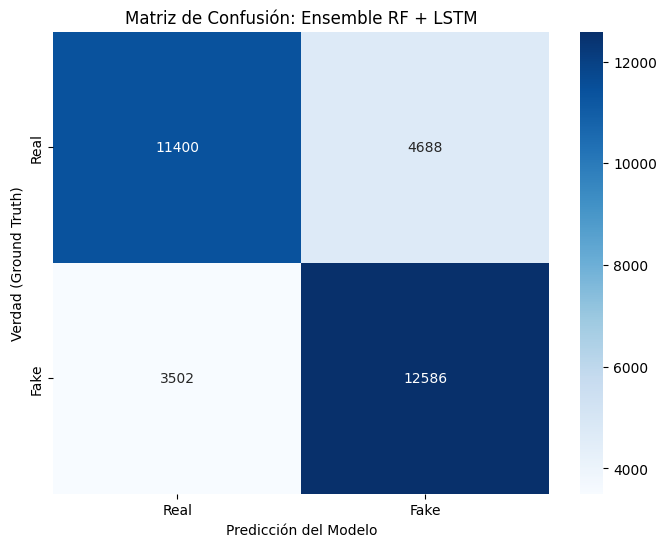

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generar matriz
cm = confusion_matrix(y_test, y_pred_ensemble)

# Visualizar
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Real', 'Fake'],
            yticklabels=['Real', 'Fake'])
plt.xlabel('Predicción del Modelo')
plt.ylabel('Verdad (Ground Truth)')
plt.title('Matriz de Confusión: Ensemble RF + LSTM')
plt.show()